# Wiener benchmark: noise scale, assumptions and interpretation
This notebook supports the reviewer's **minimum requirement**: explain the random-walk assumption, the units and choice of $\sigma$, and the implications for the reported benchmark comparisons.

It keeps the existing model. There is **no AR(1) model and no repeated synthetic validation**. Calculations are analytical diagnostics and summaries of annual records. The final window is used for a focused comparison; optional broader analyses are not required to run this notebook.

A prescribed $\sigma=1$ mm can be described as a reference amplitude. A claim that it is empirically calibrated requires evidence. This notebook measures its relationship to observed variability without presuming that the chosen value is validated.

Sections 1–3 work without data. Then set `DATA_DIR` and proceed cell by cell. NumPy, SciPy, pandas and Matplotlib are required.


## 1. Settings
The defaults use 70-year windows and **75% completeness**, matching the earlier Wiener benchmark call. 

`DATA_DIR` must contain the original PSMSL annual `filelist.txt` and `data/` folder. The station-decision CSV alone does not contain the annual increments needed here.

`scope='positive_selected'` freezes the observed positive/significant station set. `all_eligible` uses every completeness-qualified station. Full-record drifts use all available observations in the input snapshot, including years outside the diagnostic window, matching the stated original construction.


In [1]:
from pathlib import Path
from datetime import datetime
import os, glob, json, hashlib
import numpy as np
import scipy
from scipy import stats
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path('../data/rlr_annual')
OUTPUT_DIR = Path('wiener_benchmark_diagnostics')
CONFIG = dict(window_length=70,end_year=2019,completeness=0.75,
              pcrit=0.01,drift_min_years=30,scope='positive_selected',
              sample_fraction=0.5,sigma_values=[0.0,1.0,5.0,10.0],
              include_empirical_scale=True,min_pairs=10,
              diagnostic_lags=[1,2,5,10])
print('Data:',DATA_DIR.resolve())
print(CONFIG)


Data: C:\Users\User\work\IPGP\Climate\data\rlr_annual
{'window_length': 70, 'end_year': 2019, 'completeness': 0.75, 'pcrit': 0.01, 'drift_min_years': 30, 'scope': 'positive_selected', 'sample_fraction': 0.5, 'sigma_values': [0.0, 1.0, 5.0, 10.0], 'include_empirical_scale': True, 'min_pairs': 10, 'diagnostic_lags': [1, 2, 5, 10]}


## 2. What the model and its noise parameter mean
For one-year steps,
$$z_n(t+1)=z_n(t)+b_n\Delta t+\xi_n(t),\quad \Delta t=1\ \mathrm{yr},\quad \xi_n(t)\sim N(0,\sigma^2).$$
Here $z_n$ and $\xi_n$ are in mm; $b_n$ is in mm/yr; $\sigma$ is the standard deviation in **mm of a one-year increment**. If a continuous-time diffusion coefficient is used instead, it has units mm/$\sqrt{\mathrm{yr}}$ and its increment SD is multiplied by $\sqrt{\Delta t}$.

The random-walk assumption supplies a tractable benchmark for accumulated independent Gaussian disturbances. Each disturbance persists in subsequent levels. After $k$ annual steps, the noise variance is $k\sigma^2$. This specifies the temporal structure as well as the amplitude: rescaling $\sigma$ changes the magnitude, but preserves that accumulation.

For complete zero-drift records, multiplying $\sigma$ multiplies all fitted slopes and the subsampling SD of their means by the same factor. With heterogeneous fixed drifts, the **relative sizes of the drift and noise contributions change** when $\sigma$ changes. Thus $\sigma=1$ is a convenient reference scale for pure diffusion, and a substantive relative-amplitude choice in the drift benchmark.

### Exact slope-noise calculation
OLS with an intercept gives slope weights $a_i=(t_i-\bar t)/\sum_j(t_j-\bar t)^2$ at observed years (zero at missing years). For annual innovations, let $q_k=\sum_{i\ge k}a_i$ for increments after the first grid year. Then
$$\operatorname{Var}(\hat b-b)=\sigma^2\sum_k q_k^2.$$
The notebook evaluates these weights exactly, including gaps. For $T$ complete annual observations, the familiar approximation is $\operatorname{SD}(\hat b)\simeq\sigma\sqrt{6/(5T)}$ in mm/yr. There are $T-1$ increments when the first level is fixed.


In [2]:
import os
import glob
import numpy as np


def read_annual(directory_name):
    """
    Reads PSMSL RLR annual data directory.
    
    Parameters:
        directory_name (str): Path to unzipped PSMSL directory containing 
                              'filelist.txt' and the 'data/' folder.
                              
    Returns:
        list of dict: Each dict corresponds to a station with keys:
            'id', 'latitude', 'longitude', 'name', 'coastline',
            'stationcode', 'stationflag', 'year', 'height',
            'interpolated', 'isMtl', 'dataflag'
    """
    if not os.path.isdir(directory_name):
        raise FileNotFoundError(f"Cannot find directory: {directory_name}")

    data_dir = os.path.join(directory_name, 'data')
    if not os.path.isdir(data_dir):
        raise FileNotFoundError(
            f"Cannot find data directory {data_dir}. "
            "Please ensure the path points to the root unzipped folder, not 'data/' itself."
        )

    # 1. Parse filelist.txt catalogue
    cat_file = os.path.join(directory_name, 'filelist.txt')
    if not os.path.isfile(cat_file):
        raise FileNotFoundError(f"Could not find catalogue file: {cat_file}")

    catalogue = {}
    with open(cat_file, 'r', encoding='utf-8', errors='ignore') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            parts = line.split(';')
            if len(parts) < 7:
                continue
            st_id = int(parts[0].strip())
            catalogue[st_id] = {
                'latitude': float(parts[1].strip()),
                'longitude': float(parts[2].strip()),
                'name': parts[3].strip(),
                'coastline': int(parts[4].strip()) if parts[4].strip() else None,
                'stationcode': int(parts[5].strip()) if parts[5].strip() else None,
                'stationflag': parts[6].strip() == 'Y'
            }

    # 2. Match .rlrdata files
    file_paths = glob.glob(os.path.join(data_dir, '*.rlrdata'))
    data = []

    for path in sorted(file_paths):
        filename = os.path.basename(path)
        st_id = int(filename.split('.')[0])
        
        meta = catalogue.get(st_id, {
            'latitude': np.nan, 'longitude': np.nan, 'name': '',
            'coastline': None, 'stationcode': None, 'stationflag': False
        })

        # 3. Read station time series
        # Format: Year; Height; InterpolatedFlag; QualityFlags(3 digits)
        years, heights, interpolated, is_mtl, dataflag = [], [], [], [], []
        
        with open(path, 'r', encoding='utf-8', errors='ignore') as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                parts = line.split(';')
                if len(parts) < 4:
                    continue

                yr = int(parts[0].strip())
                raw_h = float(parts[1].strip())
                h = np.nan if raw_h == -99999 else raw_h
                interp = parts[2].strip() == 'Y'

                # Flags: 3-character string (e.g. "000")
                flags_str = parts[3].strip()
                flags_str = flags_str.ljust(3, '0')
                mtl = flags_str[1] == '1'
                dflag = flags_str[2] == '1'

                years.append(yr)
                heights.append(h)
                interpolated.append(interp)
                is_mtl.append(mtl)
                dataflag.append(dflag)

        station_record = {
            'id': st_id,
            'latitude': meta['latitude'],
            'longitude': meta['longitude'],
            'name': meta['name'],
            'coastline': meta['coastline'],
            'stationcode': meta['stationcode'],
            'stationflag': meta['stationflag'],
            'year': np.array(years, dtype=int),
            'height': np.array(heights, dtype=float),
            'interpolated': np.array(interpolated, dtype=bool),
            'isMtl': np.array(is_mtl, dtype=bool),
            'dataflag': np.array(dataflag, dtype=bool)
        }
        data.append(station_record)

    return data


In [3]:
def slope_noise_coefficient(years, observed=None):
    """Exact SD of an OLS slope for unit independent annual random-walk increments.
    years is a complete consecutive calendar grid; observed marks available levels.
    A fitted intercept removes the arbitrary initial level.
    """
    years=np.asarray(years,float)
    if len(years)<3 or not np.allclose(np.diff(years),1):
        raise ValueError('Use a consecutive annual grid of at least three years.')
    mask=np.ones(len(years),bool) if observed is None else np.asarray(observed,bool)
    if mask.shape!=years.shape or mask.sum()<3: raise ValueError('Invalid observation mask.')
    x=years[mask]-years[mask].mean()
    a=np.zeros(len(years));a[mask]=x/(x@x)
    q=np.cumsum(a[::-1])[::-1][1:]
    return float(np.sqrt(q@q))


def global_station_drifts(series,min_years=30):
    drifts={};fitted=[]
    for st in series:
        t=np.asarray(st['year'],float);h=np.asarray(st['height'],float)
        ok=np.isfinite(h)&(h!=-99999)
        if ok.sum()>=min_years:
            b=float(stats.linregress(t[ok],h[ok]).slope)
            fitted.append(b);drifts[str(st['id'])]=(b,False)
    if not fitted: raise ValueError('No station has enough valid years to estimate a drift.')
    mean=float(np.mean(fitted))
    for st in series:
        if str(st['id']) not in drifts: drifts[str(st['id'])]=(mean,True)
    return drifts


def adjacent_corr(values, times):
    values=np.asarray(values,float);times=np.asarray(times,int)
    pairs=np.where(np.diff(times)==1)[0]
    if len(pairs)<3 or np.std(values[pairs])==0 or np.std(values[pairs+1])==0:
        return np.nan,len(pairs)
    return float(np.corrcoef(values[pairs],values[pairs+1])[0,1]),len(pairs)


def empirical_window(series,drifts,cfg):
    start=cfg['end_year']-cfg['window_length']+1
    grid=np.arange(start,cfg['end_year']+1)
    rows=[];lags=[]
    for st in series:
        t=np.asarray(st['year'],int);h=np.asarray(st['height'],float)
        if not len(t):continue
        if len(t)!=len(h) or np.any(np.diff(t)<=0):raise ValueError('Station years must be unique and sorted.')
        if t[0]>grid[0] or t[-1]<grid[-1]:continue
        y=np.full(len(grid),np.nan)
        inside=(t>=grid[0])&(t<=grid[-1]);y[t[inside]-grid[0]]=h[inside]
        ok=np.isfinite(y)&(y!=-99999)
        if ok.sum()/len(grid)<cfg['completeness']:continue
        fit=stats.linregress(grid[ok],y[ok])
        selected=bool(fit.slope>0 and fit.pvalue<=cfg['pcrit'])
        pair=ok[1:]&ok[:-1]
        increments=(y[1:]-y[:-1])[pair]
        inc_year=grid[:-1][pair]
        n=len(increments)
        inc_sd=float(np.std(increments,ddof=1)) if n>=cfg['min_pairs'] else np.nan
        inc_width=float(np.quantile(increments,.8)-np.quantile(increments,.2)) if n>=cfg['min_pairs'] else np.nan
        rho,npairs=adjacent_corr(increments,inc_year)
        b,imputed=drifts[str(st['id'])]
        rows.append(dict(station_id=str(st['id']),name=st.get('name',''),n_obs=int(ok.sum()),
            selected=selected,local_slope=fit.slope,p_two_sided=fit.pvalue,
            full_record_drift=b,drift_imputed=imputed,n_annual_pairs=n,
            annual_increment_sd=inc_sd,annual_increment_p20_p80=inc_width,
            increment_rho1=rho,n_increment_correlation_pairs=npairs,
            slope_sd_per_unit_sigma=slope_noise_coefficient(grid,ok)))
        v1=inc_sd**2
        for lag in cfg['diagnostic_lags']:
            pairs=ok[lag:]&ok[:-lag]
            changes=(y[lag:]-y[:-lag])[pairs]
            v=float(np.var(changes,ddof=1)) if len(changes)>=cfg['min_pairs'] else np.nan
            lags.append(dict(station_id=str(st['id']),selected=selected,lag_years=lag,n_pairs=len(changes),
                             change_variance=v,variance_per_year=v/lag,
                             ratio_to_lag1=v/(lag*v1) if np.isfinite(v1) and v1>0 else np.nan))
    if not rows:raise ValueError('No eligible stations; check paths and settings.')
    return pd.DataFrame(rows),pd.DataFrame(lags)


def scale_diagnostics(stations,cfg):
    pool=stations[stations.selected].copy() if cfg['scope']=='positive_selected' else stations.copy()
    if cfg['scope'] not in ['positive_selected','all_eligible']:raise ValueError('Unknown scope.')
    if len(pool)<2:raise ValueError('At least two stations are needed for dispersion diagnostics.')
    inc=pool.annual_increment_sd.dropna()
    empirical_scale=float(inc.median()) if len(inc) else np.nan
    n=len(pool);m=int(np.floor(n*cfg['sample_fraction']+.5))
    if not 1<=m<=n:raise ValueError('Invalid subsample size.')
    sb2=float(np.var(pool.full_record_drift,ddof=1))
    c_complete=slope_noise_coefficient(np.arange(cfg['window_length']))
    scales=[(f'prescribed sigma={s:g}',float(s)) for s in cfg['sigma_values']]
    if cfg['include_empirical_scale'] and np.isfinite(empirical_scale):
        scales.append(('observed median increment SD (illustrative)',empirical_scale))
    rows=[]
    factor=(1-m/n)/m
    for mask_mode in ['complete_records','empirical_masks']:
        c=np.full(n,c_complete) if mask_mode=='complete_records' else pool.slope_sd_per_unit_sigma.to_numpy()
        c2=float(np.mean(c*c))
        for label,sigma in scales:
            noise_var=sigma*sigma*c2
            rows.append(dict(mask_mode=mask_mode,scale_label=label,sigma_mm=sigma,N=n,m=m,
                drift_sd=np.sqrt(sb2),station_noise_rms_sd=np.sqrt(noise_var),
                noise_variance_fraction=noise_var/(sb2+noise_var) if sb2+noise_var>0 else np.nan,
                rms_subsample_sd_zero_drift=np.sqrt(factor*noise_var),
                rms_subsample_sd_with_drifts=np.sqrt(factor*(sb2+noise_var)),
                noise_sd_full_station_mean=sigma*np.sqrt(np.sum(c*c))/n,
                sigma_equal_drift_and_noise=np.sqrt(sb2/c2)))
    return pool,pd.DataFrame(rows)


def brief_summary(stations,pool,table,cfg):
    rows=[]
    for label,d in [('all eligible',stations),('diagnostic scope',pool)]:
        for col in ['annual_increment_sd','annual_increment_p20_p80','increment_rho1','slope_sd_per_unit_sigma']:
            x=d[col].dropna()
            rows.append(dict(group=label,quantity=col,n=len(x),
                q25=x.quantile(.25),median=x.median(),q75=x.quantile(.75)))
    return pd.DataFrame(rows)


def plot_diagnostics(pool,table,cfg):
    fig,axes=plt.subplots(1,3,figsize=(14,4.2),layout='constrained')
    x=pool.annual_increment_sd.dropna().to_numpy()
    axes[0].hist(x,bins='auto',color='steelblue',alpha=.8)
    axes[0].axvline(1,color='black',ls='--',label='Reference sigma = 1 mm')
    axes[0].set_xlabel('Within-station annual increment SD, mm')
    axes[0].set_ylabel('Number of stations');axes[0].legend(fontsize=8)
    complete=table[table.mask_mode=='complete_records'].sort_values('sigma_mm')
    masked=table[table.mask_mode=='empirical_masks'].sort_values('sigma_mm')
    axes[1].plot(complete.sigma_mm,complete.station_noise_rms_sd,'o-',label='Complete records')
    axes[1].plot(masked.sigma_mm,masked.station_noise_rms_sd,'s--',label='Empirical masks')
    axes[1].set_ylabel('RMS station slope-noise SD, mm/yr')
    axes[1].legend(fontsize=8)
    axes[2].plot(complete.sigma_mm,complete.rms_subsample_sd_zero_drift,'o-',label='Zero drift')
    axes[2].plot(complete.sigma_mm,complete.rms_subsample_sd_with_drifts,'s-',label='Empirical fixed drifts')
    axes[2].set_ylabel('RMS conditional subsampling SD, mm/yr')
    axes[2].legend(fontsize=8)
    for i,ax in enumerate(axes):
        ax.set_title(f'({chr(97+i)})',loc='left');ax.grid(ls=':',alpha=.4)
        if i:ax.set_xlabel('Annual increment noise SD, sigma (mm)')
    fig.suptitle(f'{cfg["end_year"]-cfg["window_length"]+1}–{cfg["end_year"]}; fixed station set')
    return fig


def data_fingerprint(series):
    h=hashlib.sha256()
    for st in series:
        h.update(str(st['id']).encode())
        h.update(np.asarray(st['year'],dtype='<i8').tobytes())
        h.update(np.asarray(st['height'],dtype='<f8').tobytes())
    return h.hexdigest()


## 3. Analytical checks and reference numbers (no data needed)
The first table quantifies the consequence of sigma = 1. The Gaussian central-60% width is a within-station increment reference, not a reconstruction of Figure 2's across-station distribution.


In [4]:
reference=[]
for T in [60,70]:
    years=np.arange(T)
    c=slope_noise_coefficient(years)
    a=(years-years.mean())/np.sum((years-years.mean())**2)
    K=np.minimum.outer(years,years)
    assert np.isclose(c*c,a@K@a)
    mask=np.ones(T,bool);mask[4:9]=False
    x=years[mask]-years[mask].mean();weights=x/(x@x)
    assert np.isclose(slope_noise_coefficient(years,mask)**2,
                      weights@K[np.ix_(mask,mask)]@weights)
    reference.append(dict(annual_observations=T,annual_increments=T-1,
        sigma_mm=1.,exact_slope_sd_mm_per_year=c,
        approximate_slope_sd_mm_per_year=np.sqrt(6/(5*T)),
        final_level_noise_sd_mm=np.sqrt(T-1)))
reference_table=pd.DataFrame(reference)
display(reference_table)
print('Central 60% width for Gaussian increments at sigma=1:',
      stats.norm.ppf(.8)-stats.norm.ppf(.2),'mm')
print('Exact slope-weight and missing-year covariance checks passed.')


,annual_observations,annual_increments,sigma_mm,exact_slope_sd_mm_per_year,approximate_slope_sd_mm_per_year,final_level_noise_sd_mm
0,60,59,1.0,0.141461,0.141421,7.681146
1,70,69,1.0,0.130957,0.130931,8.306624


Central 60% width for Gaussian increments at sigma=1: 1.6832424671458286 mm
Exact slope-weight and missing-year covariance checks passed.


## 4. Read annual data and compute fixed drifts
The embedded reader retains the previous handling of quality flags: flags are read but not used for additional exclusions. Heights of -99999 are missing. Station records must span the full window and meet completeness.

Full-record drift fits require at least 30 valid annual observations; other stations receive the catalogue mean of estimable drifts. These empirical drifts include all contributions to observed trends and should not be labelled independently measured VLM.


In [5]:
series=read_annual(str(DATA_DIR))
if not series: raise ValueError('No annual station files found.')
drifts=global_station_drifts(series,min_years=CONFIG['drift_min_years'])
print('Catalogue stations:',len(series))
print('Drifts imputed:',sum(v[1] for v in drifts.values()))


Catalogue stations: 1548
Drifts imputed: 867


## 5. Compare the reference amplitude with observed increments
Annual changes use **only pairs one calendar year apart**. Gaps are not bridged. Each station's temporal increment SD and 20th–80th percentile width are calculated separately; the summary gives equal weight to stations. A constant drift shifts annual increments without changing their SD.

These statistics differ from Figure 2, which compares stations at selected dates. Cross-station heterogeneity, regional common signals and local anomalies can all contribute to those distributions. Neither statistic alone identifies the correct long-term stochastic model.

The diagnostic scope is fixed from empirical OLS selection with two-sided p <= 0.01. No synthetic significance filter is reapplied when sigma changes.


In [6]:
station_diagnostics, lag_diagnostics = empirical_window(series,drifts,CONFIG)
pool, scale_table = scale_diagnostics(station_diagnostics,CONFIG)
observed_summary=brief_summary(station_diagnostics,pool,scale_table,CONFIG)
print('Eligible stations:',len(station_diagnostics))
print('Observed positive/significant stations:',int(station_diagnostics.selected.sum()))
print('Stations in diagnostic scope:',len(pool))
print('Full-record drift SD in this scope:',pool.full_record_drift.std(ddof=1),'mm/yr')
display(observed_summary.round(6))
display(pool[['station_id','name','local_slope','full_record_drift',
              'n_annual_pairs','annual_increment_sd','slope_sd_per_unit_sigma']].head(10))


Eligible stations: 133
Observed positive/significant stations: 87
Stations in diagnostic scope: 87
Full-record drift SD in this scope: 2.1150486174823153 mm/yr


,group,quantity,n,q25,median,q75
0,all eligible,annual_increment_sd,133,35.163850,44.414177,57.578784
1,all eligible,annual_increment_p20_p80,133,58.600000,70.200000,95.200000
2,all eligible,increment_rho1,133,-0.424670,-0.348301,-0.275974
3,all eligible,slope_sd_per_unit_sigma,133,0.130536,0.130837,0.130957
4,diagnostic scope,annual_increment_sd,87,32.073902,39.535409,46.687360
5,diagnostic scope,annual_increment_p20_p80,87,53.300000,64.800000,76.600000
6,diagnostic scope,increment_rho1,87,-0.363498,-0.326090,-0.239032
7,diagnostic scope,slope_sd_per_unit_sigma,87,0.130538,0.130898,0.130957


,station_id,name,local_slope,full_record_drift,n_annual_pairs,annual_increment_sd,slope_sd_per_unit_sigma
0,1,BREST,1.957339,1.018824,66,33.501004,0.133860
1,10,SAN FRANCISCO,1.974860,1.499607,67,50.932316,0.130999
2,11,WARNEMUNDE 2,1.611836,1.266466,67,54.464201,0.130898
3,111,FREMANTLE,1.744129,1.686184,65,56.431089,0.130539
4,112,FERNANDINA BEACH,2.592058,2.173730,60,41.505428,0.130260
5,12,NEW YORK (THE BATTERY),3.166371,2.894097,63,38.435475,0.130606
7,127,SEATTLE,2.007436,2.056106,69,41.426205,0.130957
8,130,ABURATSUBO,3.572373,3.596357,69,25.306543,0.130957
9,132,WAJIMA,0.594265,0.114747,65,29.069587,0.130770
11,135,PHILADELPHIA (PIER 9N),3.496862,3.029114,64,46.965444,0.130689


## 6. Quantify the relative drift and noise contributions
For a **fixed** empirical station set, write synthetic fitted slopes as $\hat b_n=b_n+e_n$. Independent Gaussian annual innovations give $\operatorname{Var}(e_n)=\sigma^2 c_n^2$, with $c_n$ calculated from the sampling times. Then
$$E[S^2_{\hat b}]=S_b^2+\sigma^2\,\overline{c_n^2}.$$
For a random subsample of $m$ out of $N$ stations without replacement,
$$E[\operatorname{Var}(\overline{\hat b}_m\mid\hat b)]=\frac{1-m/N}{m}\left(S_b^2+\sigma^2\overline{c_n^2}\right).$$
The displayed square root is the **root-mean-square conditional subsampling SD**, not the expectation of the SD itself. These are diagnostics for the benchmark's **mean-rate dispersion**, not the trimmed median estimator $M'$.

Both complete synthetic records and the empirical observation masks are shown. The complete-record version is closest to a benchmark with synthetic full-window trajectories; the mask version quantifies sensitivity to observation gaps. This is not a replay of the original station-entry/extension simulation.

The table also shows the noise SD of the full station mean across independent stochastic realizations. This is a different uncertainty quantity from conditional station subsampling. In the half-sample, independent-noise case, some numerical values coincide.

The empirically derived extra amplitude is the median within-station annual increment SD. It illustrates the consequence of matching that short-term scale **within a random walk**; it is not an endorsed calibration of multidecadal noise. The specified amplitudes 5 and 10 mm are sensitivity values, not fitted estimates.


In [7]:
display(scale_table.round(6))
baseline=scale_table[(scale_table.mask_mode=='complete_records')&
                     (scale_table.scale_label=='prescribed sigma=1')].iloc[0]
print('At sigma=1, station slope-noise SD:',baseline.station_noise_rms_sd,'mm/yr')
print('Noise contribution to expected cross-station variance:',
      100*baseline.noise_variance_fraction,'%')
print('Increment sigma giving equal drift and noise variance:',
      baseline.sigma_equal_drift_and_noise,'mm')


,mask_mode,scale_label,sigma_mm,N,m,drift_sd,station_noise_rms_sd,noise_variance_fraction,rms_subsample_sd_zero_drift,rms_subsample_sd_with_drifts,noise_sd_full_station_mean,sigma_equal_drift_and_noise
0,complete_records,prescribed sigma=0,0.000000,87,44,2.115049,0.000000,0.000000,0.000000,0.224165,0.000000,16.150654
1,complete_records,prescribed sigma=1,1.000000,87,44,2.115049,0.130957,0.003819,0.013880,0.224595,0.014040,16.150654
2,complete_records,prescribed sigma=5,5.000000,87,44,2.115049,0.654787,0.087460,0.069398,0.234662,0.070201,16.150654
3,complete_records,prescribed sigma=10,10.000000,87,44,2.115049,1.309575,0.277128,0.138796,0.263656,0.140401,16.150654
4,complete_records,observed median increment SD (illustrative),39.535409,87,44,2.115049,5.177457,0.856985,0.548738,0.592759,0.555082,16.150654
5,empirical_masks,prescribed sigma=0,0.000000,87,44,2.115049,0.000000,0.000000,0.000000,0.224165,0.000000,16.119400
6,empirical_masks,prescribed sigma=1,1.000000,87,44,2.115049,0.131211,0.003834,0.013907,0.224596,0.014067,16.119400
7,empirical_masks,prescribed sigma=5,5.000000,87,44,2.115049,0.656057,0.087770,0.069533,0.234702,0.070337,16.119400
8,empirical_masks,prescribed sigma=10,10.000000,87,44,2.115049,1.312114,0.277905,0.139066,0.263798,0.140673,16.119400
9,empirical_masks,observed median increment SD (illustrative),39.535409,87,44,2.115049,5.187495,0.857459,0.549802,0.593744,0.556158,16.119400


At sigma=1, station slope-noise SD: 0.13095745742672757 mm/yr
Noise contribution to expected cross-station variance: 0.3819073195013165 %
Increment sigma giving equal drift and noise variance: 16.150654258584037 mm


## 7. Plot the implications of the amplitude choice
Panel (a) compares the empirical within-station increment scales with sigma = 1. Panel (b) shows noise in station slope estimates. Panel (c) shows the RMS conditional subsampling dispersion for independent complete synthetic records with zero or fixed empirical drifts. Station membership is held fixed throughout this comparison.


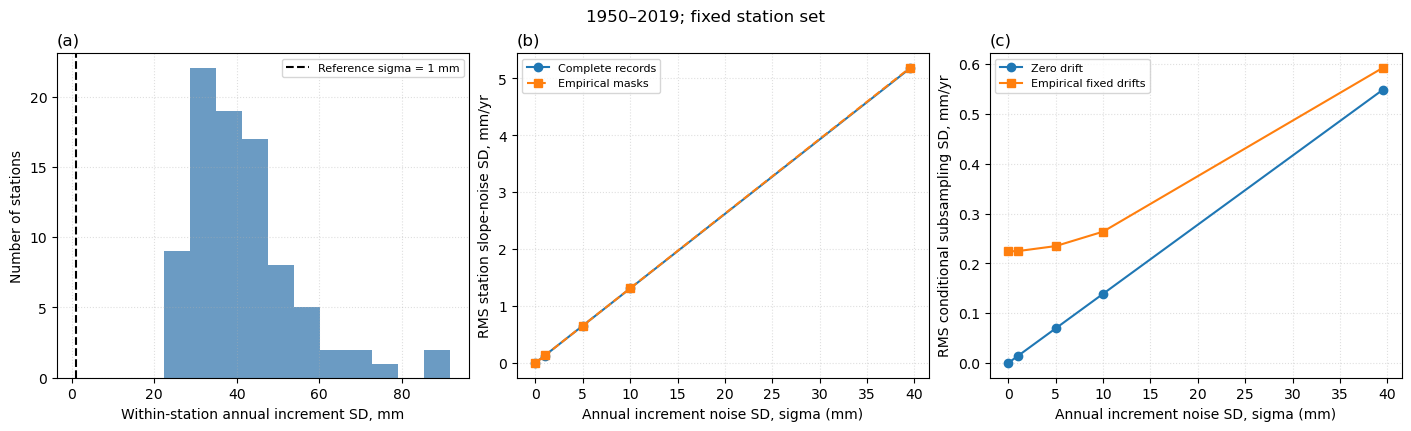

In [8]:
fig=plot_diagnostics(pool,scale_table,CONFIG)
plt.show()


## 8. Optional descriptive check of the random-walk assumption
Leave this off for the minimum amplitude calculation. If enabled, compare the observed variance of $k$-year changes with $k$ times the one-year change variance. Independent random-walk increments have population variance proportional to $k$.

Ratios are computed within station and summarized by their median; at least 10 pairs are required at each lag. The contributing station pool can differ by lag and its size is reported. These finite-window estimates use overlapping changes and estimated means, so the table is descriptive rather than a goodness-of-fit test. It does not establish stationarity or identify an alternative noise model.


In [9]:
RUN_LAG_DIAGNOSTIC = False
if RUN_LAG_DIAGNOSTIC:
    chosen=lag_diagnostics[lag_diagnostics.station_id.isin(pool.station_id)]
    lag_summary=chosen.groupby('lag_years').agg(
        n_stations=('ratio_to_lag1','count'),
        median_ratio=('ratio_to_lag1','median'),
        median_variance_per_year=('variance_per_year','median'))
    display(lag_summary)
else:
    print('Optional lag diagnostic is off.')


Optional lag diagnostic is off.


In [11]:
display(scale_table.round(6))

,mask_mode,scale_label,sigma_mm,N,m,drift_sd,station_noise_rms_sd,noise_variance_fraction,rms_subsample_sd_zero_drift,rms_subsample_sd_with_drifts,noise_sd_full_station_mean,sigma_equal_drift_and_noise
0,complete_records,prescribed sigma=0,0.000000,87,44,2.115049,0.000000,0.000000,0.000000,0.224165,0.000000,16.150654
1,complete_records,prescribed sigma=1,1.000000,87,44,2.115049,0.130957,0.003819,0.013880,0.224595,0.014040,16.150654
2,complete_records,prescribed sigma=5,5.000000,87,44,2.115049,0.654787,0.087460,0.069398,0.234662,0.070201,16.150654
3,complete_records,prescribed sigma=10,10.000000,87,44,2.115049,1.309575,0.277128,0.138796,0.263656,0.140401,16.150654
4,complete_records,observed median increment SD (illustrative),39.535409,87,44,2.115049,5.177457,0.856985,0.548738,0.592759,0.555082,16.150654
5,empirical_masks,prescribed sigma=0,0.000000,87,44,2.115049,0.000000,0.000000,0.000000,0.224165,0.000000,16.119400
6,empirical_masks,prescribed sigma=1,1.000000,87,44,2.115049,0.131211,0.003834,0.013907,0.224596,0.014067,16.119400
7,empirical_masks,prescribed sigma=5,5.000000,87,44,2.115049,0.656057,0.087770,0.069533,0.234702,0.070337,16.119400
8,empirical_masks,prescribed sigma=10,10.000000,87,44,2.115049,1.312114,0.277905,0.139066,0.263798,0.140673,16.119400
9,empirical_masks,observed median increment SD (illustrative),39.535409,87,44,2.115049,5.187495,0.857459,0.549802,0.593744,0.556158,16.119400


## 9. Interpretation for the manuscript and response letter
Use the generated numbers to explain the chosen benchmark, rather than to infer a physical hierarchy from it.

**Random-walk rationale.** The Wiener process provides a mathematically specified reference for accumulated Gaussian disturbances. Its independent increments yield explicit amplitude and sample-size relations. This is the benchmark's analytical purpose. Its level variance grows with elapsed time, which is a substantive idealization of temporal behaviour.

**Sigma rationale.** A prescribed annual increment SD of 1 mm sets a transparent reference amplitude. For pure zero-drift diffusion, other amplitudes rescale the result. In the heterogeneous-drift model, the value sets the strength of stochastic perturbations relative to empirical drifts. If it was originally chosen for a different reason, document that actual reason; these diagnostics cannot recover the historical choice. Describe it as empirically calibrated only if an explicit calibration was performed.

**Interpretation of empirical drifts.** They are estimated from the same records used for comparison. Similarity in magnitude partly reflects those data-derived inputs. Fixed drifts change their across-station distribution over windows through membership changes; empirical window-fitted slopes can change within individual stations. This distinction helps interpret disagreement in temporal patterns.

**Spatial dependence.** The calculations in this notebook assume independent stations. In a correlated model, the covariance of station slope errors also matters. Conditional subsampling spread depends on differences between station errors, whereas uncertainty in a spatial mean can be strongly influenced by a shared component. Thus conclusions about the size of geographic-correlation effects remain specific to the implemented covariance and amplitude; no general ranking of spatial dependence versus station heterogeneity follows from sigma = 1.

**Scope.** The diagnostics characterize the stated final window and fixed station set. Changing sigma in a complete simulation with renewed significance selection can also change membership. The exact table here holds membership fixed. Rescaling an existing heterogeneous-drift curve is therefore not a substitute for rerunning that simulation.

Suggested short wording, to adapt after inspecting the results:

> The Wiener process is used as an analytically tractable benchmark for accumulated Gaussian disturbances. Its annual increments have a prescribed standard deviation of 1 mm. This reference amplitude determines the relative stochastic contribution in the heterogeneous-drift simulations. The resulting comparisons characterize the specified model and parameterization. The empirical drift terms are estimated from the observational records, while the random-walk assumption imposes variance growth with elapsed time. The observed and simulated dispersion therefore reflect both the input drift distribution and the assumed temporal covariance of the fluctuations.

Add the exact slope-noise SD and observed increment scale from Sections 3–6. If drift variance dominates at sigma = 1, report its calculated fraction and qualify any earlier general claim about the relative importance of spatial dependence.


## 10. Export
This writes the diagnostic tables, parameters, data fingerprint and figure to a new folder. No empirical results are bundled with the notebook. Share the Section 5 summary and Section 6 table to prepare the final numerical wording.


In [10]:
export_dir=OUTPUT_DIR/('export_'+datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
export_dir.mkdir(parents=True,exist_ok=False)
metadata=dict(config=CONFIG,data_sha256=data_fingerprint(series),
              numpy=np.__version__,scipy=scipy.__version__,engine='wiener-diagnostics-v1',
              calculation='analytic fixed-membership independent-station diagnostics')
(export_dir/'metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
for name,table in [('reference_numbers',reference_table),('station_diagnostics',station_diagnostics),
                   ('observed_summary',observed_summary),('noise_scale_diagnostics',scale_table)]:
    table.to_csv(export_dir/f'{name}.csv',index=False)
if RUN_LAG_DIAGNOSTIC:
    lag_diagnostics.to_csv(export_dir/'lag_diagnostics.csv',index=False)
    lag_summary.to_csv(export_dir/'lag_summary.csv')
saved_fig=plot_diagnostics(pool,scale_table,CONFIG)
saved_fig.savefig(export_dir/'wiener_diagnostics.jpg',dpi=600,bbox_inches='tight')
saved_fig.savefig(export_dir/'wiener_diagnostics.pdf',bbox_inches='tight')
plt.close(saved_fig)
print('Saved to:',export_dir.resolve())


Saved to: C:\Users\User\work\IPGP\Climate\bin\wiener_benchmark_diagnostics\export_20261124_211652_191886
